# COU 07506 Digital Signal Processing — Week 04: z-Transform Laboratory: Poles, Zeros and Stability
Name: WILLIAM KEZA OSCAR  Registration No.: 240242431351
Class: BENG24COE Group: 13 Date: 25 November 2026

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
plt.rcParams["figure.figsize"] = (9, 3.5)

## Pre-lab
**(a)** H(z) = 1/(1 − 0.9z⁻¹ + 0.81z⁻²). The poles are the roots of z² − 0.9z + 0.81 = 0:
z = 0.45 ± j0.779 = 0.9·e^{±jπ/3}. Magnitude |p| = 0.9 < 1, so the causal system is **stable**.

**(b)** X(z) = 1/[(1 − 0.5z⁻¹)(1 − 0.25z⁻¹)] = A/(1 − 0.5z⁻¹) + B/(1 − 0.25z⁻¹)
with A = 1/(1 − 0.25/0.5) = **2** and B = 1/(1 − 0.5/0.25) = **−1**.
So X(z) = 2/(1 − 0.5z⁻¹) − 1/(1 − 0.25z⁻¹), and x(n) = 2(0.5)ⁿ − (0.25)ⁿ for n ≥ 0.

## Task 4.1 — A pole-zero plotting function

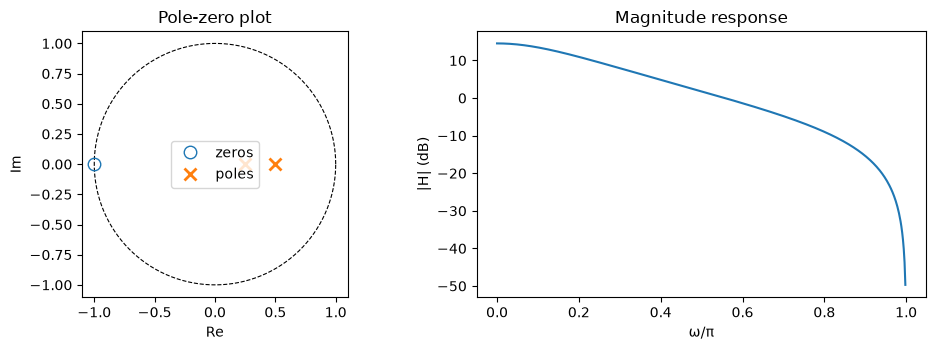

poles: [0.5  0.25]  stable: True


In [2]:
def zplane(b, a, ax=None):
    z, p, k = signal.tf2zpk(b, a)
    ax = ax or plt.gca()
    th = np.linspace(0, 2*np.pi, 400)
    ax.plot(np.cos(th), np.sin(th), "k--", lw=0.8)
    ax.plot(z.real, z.imag, "o", mfc="none", ms=9, label="zeros")
    ax.plot(p.real, p.imag, "x", ms=9, mew=2, label="poles")
    ax.set_aspect("equal"); ax.legend(); ax.set_xlabel("Re"); ax.set_ylabel("Im")
    return z, p

b, a = [1, 1], [1, -0.75, 0.125]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.6))
z, p = zplane(b, a, ax1)
ax1.set_title("Pole-zero plot")
w, H = signal.freqz(b, a, worN=512)
ax2.plot(w/np.pi, 20*np.log10(np.abs(H)))
ax2.set_title("Magnitude response"); ax2.set_xlabel("ω/π"); ax2.set_ylabel("|H| (dB)")
plt.tight_layout(); plt.show()
print("poles:", p, " stable:", np.all(np.abs(p) < 1))

## Task 4.2 — Inverse z-transform with residuez

In [3]:
r, p, k = signal.residuez([1], [1, -0.75, 0.125])
print("residues", r, "poles", p)
n = np.arange(10)
x_pf = sum(ri * pi**n for ri, pi in zip(r, p)).real
impulse = np.zeros(10); impulse[0] = 1
x_lf = signal.lfilter([1], [1, -0.75, 0.125], impulse)
print("partial fractions match lfilter:", np.allclose(x_pf, x_lf))

# the system of Task 4.1 (b = [1, 1])
r2, p2, k2 = signal.residuez([1, 1], [1, -0.75, 0.125])
print("residues", r2, "poles", p2)
h_pf = sum(ri * pi**n for ri, pi in zip(r2, p2)).real
h_lf = signal.lfilter([1, 1], [1, -0.75, 0.125], impulse)
h_cf = 6*0.5**n - 5*0.25**n
print("h(n) = 6(0.5)^n - 5(0.25)^n confirmed:", np.allclose(h_pf, h_cf) and np.allclose(h_lf, h_cf))

residues [-1.  2.] poles [0.25 0.5 ]
partial fractions match lfilter: True
residues [-5.  6.] poles [0.25 0.5 ]
h(n) = 6(0.5)^n - 5(0.25)^n confirmed: True


Comparison with pre-lab (b): the residues are 2 and −1 for the poles 0.5 and 0.25 (residuez may list the poles in the other order), which agrees with my hand calculation. For b = [1, 1] the residues are 6 and −5, so h(n) = 6(0.5)ⁿ − 5(0.25)ⁿ.

## Task 4.3 — Pole position and the impulse response

 r    | peak |H| (dB) | max|h| n=30..39 | verdict
0.50  |       5.5    | 9.313e-10      | stable
0.80  |      11.9    | 1.238e-03      | stable
0.95  |      23.2    | 2.603e-01      | stable
1.00  |      59.1    | 1.414e+00      | marginal (not stable)
1.05  |      22.8    | 8.600e+00      | UNSTABLE


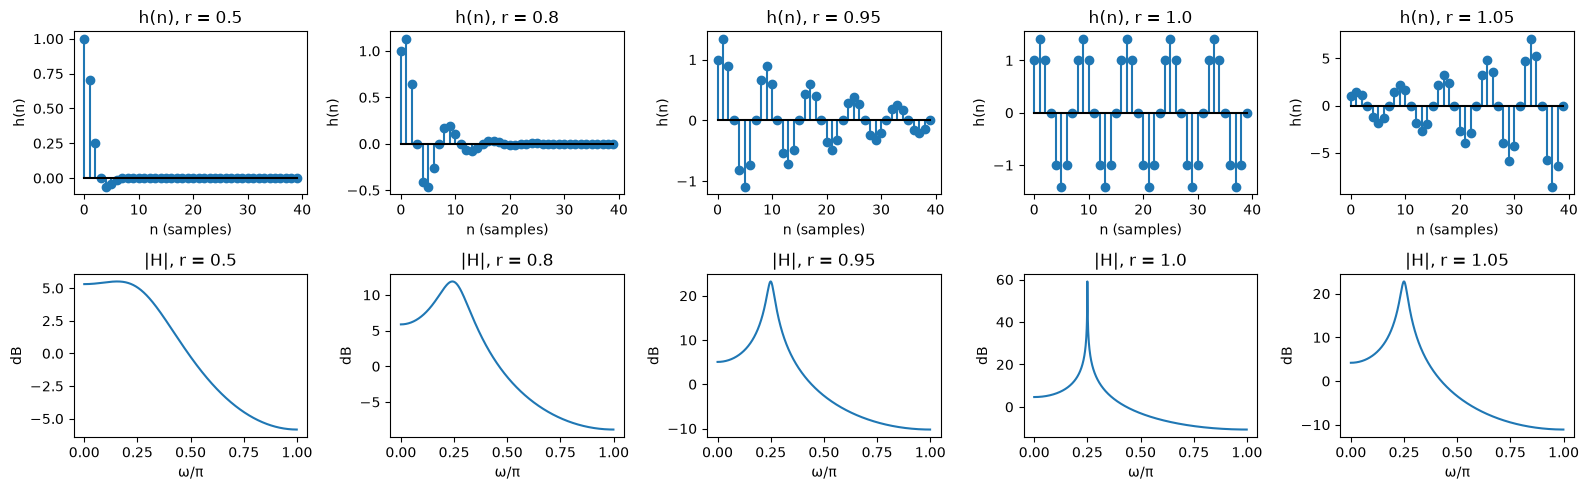

In [4]:
theta = np.pi/4
N = 40
n = np.arange(N)
imp = np.zeros(N); imp[0] = 1
rs = [0.5, 0.8, 0.95, 1.0, 1.05]
fig, axes = plt.subplots(2, 5, figsize=(16, 5))
print(" r    | peak |H| (dB) | max|h| n=30..39 | verdict")
for j, r in enumerate(rs):
    a = [1, -2*r*np.cos(theta), r**2]
    h = signal.lfilter([1], a, imp)
    w, H = signal.freqz([1], a, worN=1001)
    HdB = 20*np.log10(np.abs(H))
    axes[0, j].stem(n, h, basefmt="k-"); axes[0, j].set_title(f"h(n), r = {r}")
    axes[0, j].set_xlabel("n (samples)"); axes[0, j].set_ylabel("h(n)")
    axes[1, j].plot(w/np.pi, HdB); axes[1, j].set_title(f"|H|, r = {r}")
    axes[1, j].set_xlabel("ω/π"); axes[1, j].set_ylabel("dB")
    verdict = "stable" if r < 1 else ("marginal (not stable)" if r == 1 else "UNSTABLE")
    print(f"{r:4.2f}  | {HdB.max():9.1f}    | {np.max(np.abs(h[30:])):.3e}      | {verdict}")
plt.tight_layout(); plt.show()

Description: as r increases toward 1 the pole moves closer to the unit circle. For r = 0.5 and 0.8, h(n) is a quickly decaying oscillation and the frequency response has a low, broad peak near ω = π/4. For r = 0.95 the oscillation lasts much longer and the peak is much higher and narrower. For r = 1.0 the oscillation never decays (constant amplitude, marginally stable) and the peak is very large. For r = 1.05 the oscillation grows exponentially. **r = 1.05 is unstable** (poles outside the unit circle); r = 1.0 is marginally stable (on the circle, not BIBO stable).

## Task 4.4 — Stability of given systems

system | max|pole| | stable | max|h| last 10 samples | h grows?
H1     |    0.943  | True   | 8.857e-02          | False
H2     |    2.000  | False  | 1.153e+18          | True
H3     |    1.000  | False  | 6.667e-01          | False
H4     |    0.000  | True   | 0.000e+00          | False


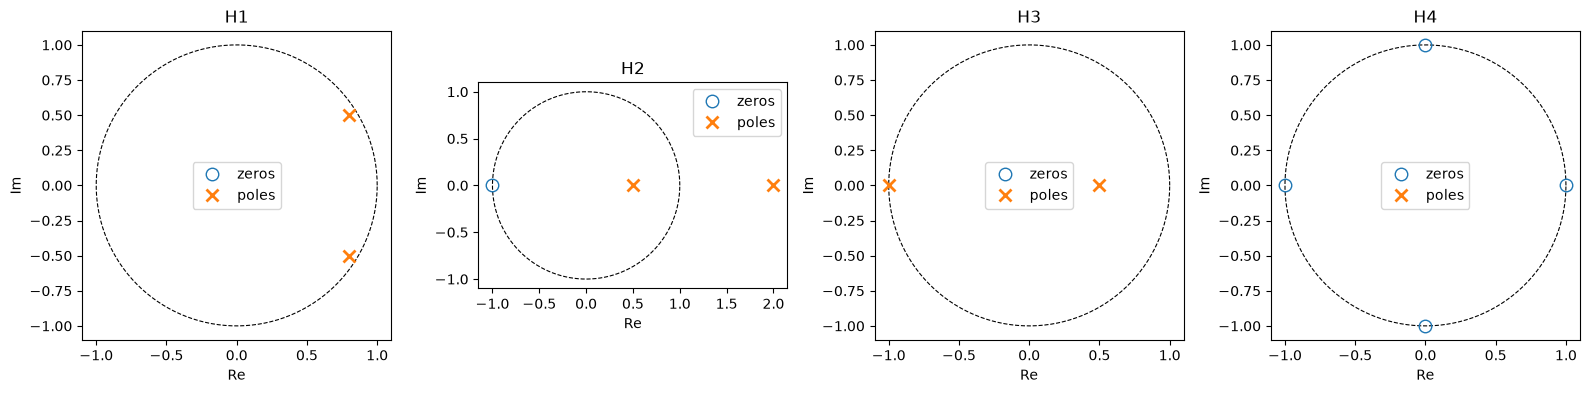

In [5]:
systems = {
 "H1": ([1], [1, -1.6, 0.89]),
 "H2": ([1, 1], [1, -2.5, 1]),
 "H3": ([1], [1, 0.5, -0.5]),
 "H4": ([1, 0, 0, 0, -1], [1]),
}
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
n = np.arange(60); imp = np.zeros(60); imp[0] = 1
print("system | max|pole| | stable | max|h| last 10 samples | h grows?")
for ax, (name, (b, a)) in zip(axes, systems.items()):
    z, p = zplane(b, a, ax); ax.set_title(name)
    h = signal.lfilter(b, a, imp)
    mp = np.max(np.abs(p)) if len(p) else 0.0
    grows = np.max(np.abs(h[-10:])) > np.max(np.abs(h[10:20])) * 1.5
    print(f"{name}     | {mp:8.3f}  | {str(bool(np.all(np.abs(p) < 1))):6s} | {np.max(np.abs(h[-10:])):.3e}          | {grows}")
plt.tight_layout(); plt.show()

Classification:

| System | Poles | Verdict |
|---|---|---|
| H1 | 0.8 ± j0.5, \|p\| = 0.943 | **stable** (h(n) decays) |
| H2 | 2 and 0.5 | **unstable** (pole at 2, h(n) grows) |
| H3 | 0.5 and −1 | **not stable**: pole on the unit circle (marginal); h(n) = (1/3)(0.5)ⁿ + (2/3)(−1)ⁿ does not decay |
| H4 | 4 poles at z = 0 (FIR), zeros at ±1, ±j | **stable** (h(n) = {1, 0, 0, 0, −1} has finite length) |

## Task 4.5 — Design a resonator

b = [ 0.0296  0.     -0.0296]  a = [ 1.     -1.3718  0.9409]


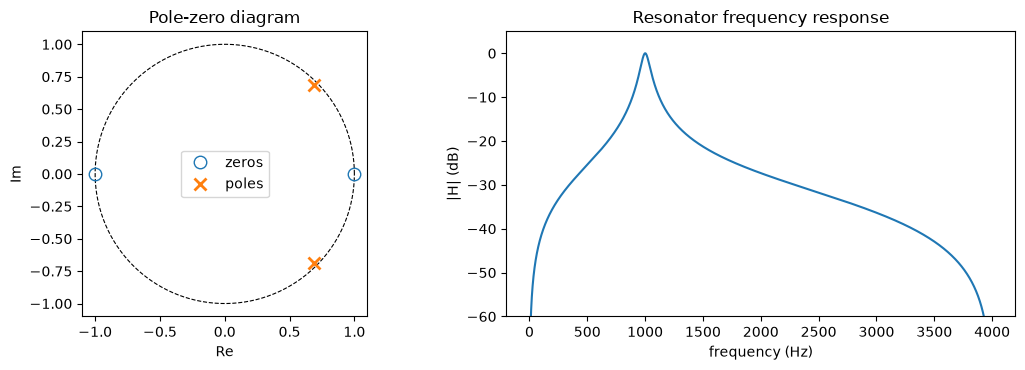

peak at 1001 Hz, -3 dB bandwidth = 76 Hz
gain at DC = -240 dB, gain at fs/2 = -97 dB


In [6]:
fs = 8000
f0 = 1000
r = 0.97
th = 2*np.pi*f0/fs                        # pole angle = pi/4
a = [1, -2*r*np.cos(th), r**2]            # poles at r e^{±jθ}
b = np.convolve([1, -1], [1, 1])          # zeros at z = +1 and z = -1  ->  [1, 0, -1]
# normalise to 0 dB gain at 1 kHz
_, H0 = signal.freqz(b, a, worN=[th])
b = np.array(b) / np.abs(H0[0])
print("b =", np.round(b, 4), " a =", np.round(a, 4))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
zplane(b, a, ax1); ax1.set_title("Pole-zero diagram")
w, H = signal.freqz(b, a, worN=4096, fs=fs)
HdB = 20*np.log10(np.abs(H) + 1e-12)
ax2.plot(w, HdB); ax2.set_ylim(-60, 5)
ax2.set_title("Resonator frequency response"); ax2.set_xlabel("frequency (Hz)"); ax2.set_ylabel("|H| (dB)")
plt.tight_layout(); plt.show()

peak_f = w[np.argmax(HdB)]
inband = w[HdB >= HdB.max() - 3]
print(f"peak at {peak_f:.0f} Hz, -3 dB bandwidth = {inband[-1]-inband[0]:.0f} Hz")
print(f"gain at DC = {HdB[0]:.0f} dB, gain at fs/2 = {HdB[-1]:.0f} dB")

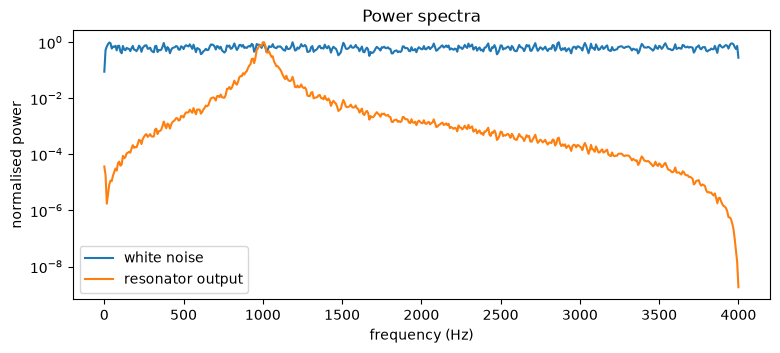

In [7]:
from IPython.display import Audio
rng = np.random.default_rng(0)
noise = rng.standard_normal(2*fs)
y = signal.lfilter(b, a, noise)
y = y / np.max(np.abs(y))
f_n, Pn = signal.welch(noise, fs, nperseg=1024)
f_y, Py = signal.welch(y, fs, nperseg=1024)
plt.semilogy(f_n, Pn/Pn.max(), label="white noise"); plt.semilogy(f_y, Py/Py.max(), label="resonator output")
plt.title("Power spectra"); plt.xlabel("frequency (Hz)"); plt.ylabel("normalised power"); plt.legend(); plt.show()
Audio(y, rate=8000)